# Plot center-site real data

Load `collected_operator_data.csv` produced by `process_twotime.py`, select center-site to center-site records, and plot the real component against frequency. Update the path and `CENTER_SITE` below if needed.

In [17]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd


def plot_center_site_data(center_data, center_site):
    plt.figure(figsize=(8, 6))
    plt.plot(center_data['omega'], center_data['real_part'], marker='o', linestyle='-')
    plt.title(f'Center-Site to Center-Site Data for Site {center_site}')
    plt.xlabel('Omega')
    plt.ylabel('Real Part')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def load_and_plot_center_site_data(run_folder, center_site, reference_site):
    csv_file = run_folder / 'collected_operator_data.csv'
    if not csv_file.is_file():
        raise FileNotFoundError(f'Data CSV not found: {csv_file}. Run process_twotime.py first.')
    
    data = pd.read_csv(csv_file)
    required = {'omega', 'center_site', 'site_index', 'real_part'}
    missing = required.difference(data.columns)
    if missing:
        raise ValueError(f'CSV is missing required columns: {sorted(missing)}')

    center_data = data.loc[
        (data['center_site'] == center_site) & (data['site_index'] == reference_site)
    ].sort_values('omega')
    
    if center_data.empty:
        raise ValueError(f'No center-site to center-site records for site {center_site}.')

    return center_data

RUN_FOLDER_Ggreat = Path('/Users/qqt/Library/CloudStorage/OneDrive-OakRidgeNationalLaboratory/Research_Projects/r_stcvsttc/code/template_folder_hubbard_chain_cv/N=8_Nup=4_Ndown=4_20261023_140645/G>_singletime_cv_N=8_Nup=4_Ndown=4_20261023_140645_steps=0')

RUN_FOLDER_Gless = Path('/Users/qqt/Library/CloudStorage/OneDrive-OakRidgeNationalLaboratory/Research_Projects/r_stcvsttc/code/template_folder_hubbard_chain_cv/N=8_Nup=4_Ndown=4_20261023_140645/G<_singletime_cv_N=8_Nup=4_Ndown=4_20261023_140645_steps=0')

CSV_FILE_great = RUN_FOLDER_Ggreat / 'collected_operator_data.csv'
CSV_FILE_gless = RUN_FOLDER_Gless / 'collected_operator_data.csv'



G_great_data = load_and_plot_center_site_data(RUN_FOLDER_Ggreat, center_site=3, reference_site=3)
G_less_data = load_and_plot_center_site_data(RUN_FOLDER_Gless, center_site=3, reference_site=3)


G_retarded_data = pd.DataFrame({
    'omega': G_great_data['omega'],
    'real_part': G_great_data['real_part'] + G_less_data['real_part']
})

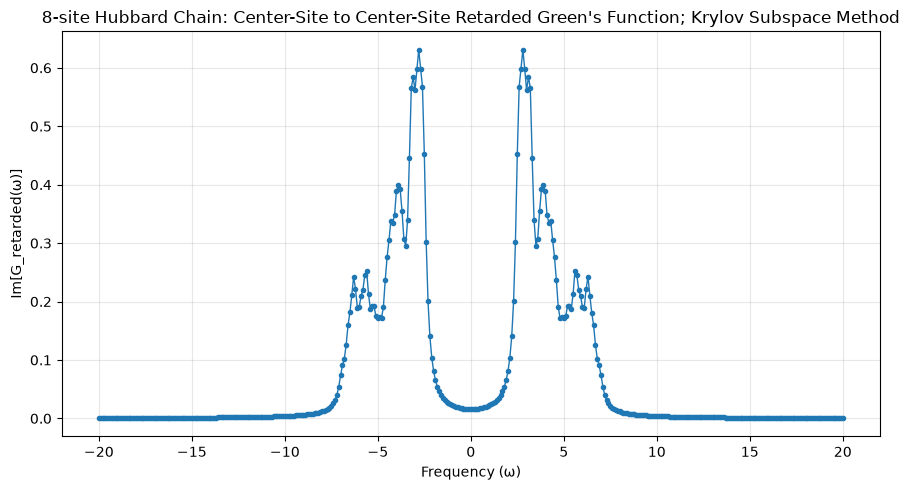

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(G_retarded_data['omega'], G_retarded_data['real_part'], marker='o', markersize=3, linewidth=1)
# ax.plot(G_great_data['omega'], G_retarded_data['real_part'], linestyle='-', linewidth=1, alpha=0.7)
# ax.plot(G_less_data['omega'], G_retarded_data['real_part'], linestyle='-', linewidth=1, alpha=0.7)
ax.set_xlabel('Frequency (ω)')
ax.set_ylabel('Im[G_retarded(ω)]')
ax.set_title('8-site Hubbard Chain: Center-Site to Center-Site Retarded Green\'s Function; Krylov Subspace Method')
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

Matrix shape: (1, 1001) (rows=t_prime, columns=t); missing entries: 0
Matrix shape: (1, 1001) (rows=t_prime, columns=t); missing entries: 0


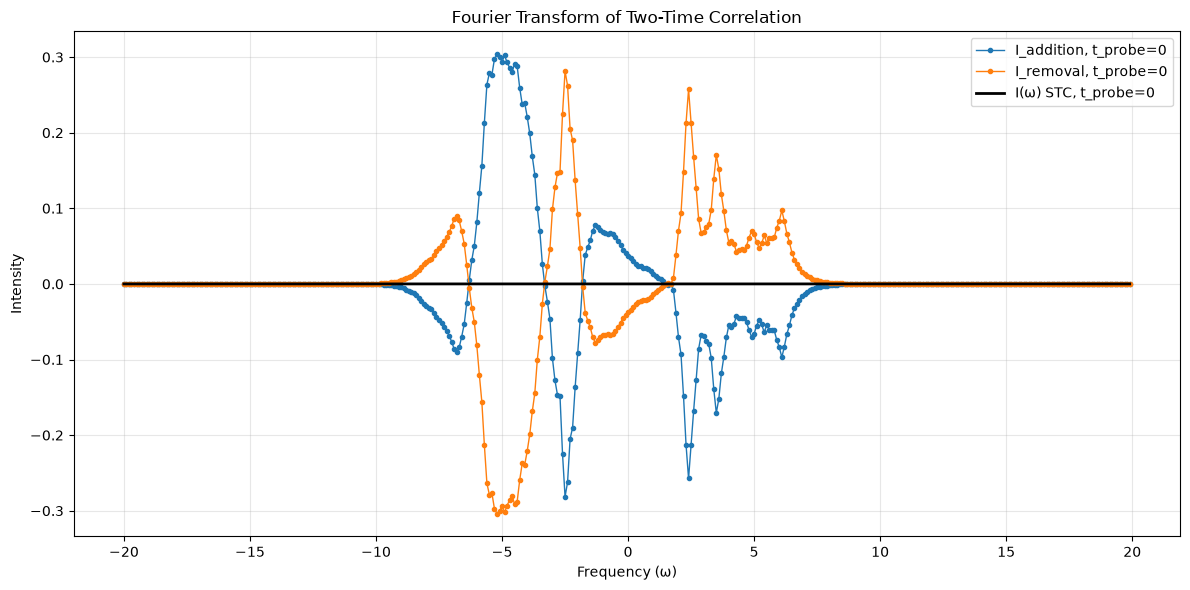

In [19]:
# Imports and file locations.
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def load_csv_data(csv_file):
    """
    Load the CSV file and return a DataFrame with the specified columns and dtypes.
    """
    # The explicit dtypes keep memory use reasonable for this large CSV.
    columns = ['t_prime', 't', 'center_site', 'site_index', 'real_part', 'imaginary_part']
    dtypes = {
        't_prime': 'float64', 't': 'float64',
        'center_site': 'int16', 'site_index': 'int16',
        'real_part': 'float64', 'imaginary_part': 'float64',
    }
    data = pd.read_csv(csv_file, usecols=columns, dtype=dtypes)
    if data.empty:
        raise ValueError('The CSV contains no data rows.')
    
    return data

def pivot_to_matrix(data, center_site, site_index):
    # Select the rows for the chosen center_site and site_index, and pivot to a matrix.
    selected = data.loc[
        (data.center_site == center_site) & (data.site_index == site_index)
    ].copy()
    if selected.empty:
        raise ValueError(f'No G data for center_site={center_site}, site_index={site_index}')

    # Do not average: each (t_prime, t) pair must occur exactly once.
    duplicates = selected.duplicated(['t_prime', 't'], keep=False)
    if duplicates.any():
        examples = selected.loc[duplicates, ['t_prime', 't']].head(10).to_dict('records')
        raise ValueError(f'Duplicate (t_prime, t) rows found. Examples: {examples}')

    # Pandas 3.13 cannot unstack a complex dtype ("No matching signature found").
    # Pivot float components independently, then construct the complex matrix.
    matrix_real = selected.pivot(index='t_prime', columns='t', values='real_part').sort_index().sort_index(axis=1)
    matrix_imag = selected.pivot(index='t_prime', columns='t', values='imaginary_part').sort_index().sort_index(axis=1)
    if not matrix_real.index.equals(matrix_imag.index) or not matrix_real.columns.equals(matrix_imag.columns):
        raise RuntimeError('Real and imaginary two-time grids do not match.')
    t_prime = matrix_real.index.to_numpy()
    t = matrix_real.columns.to_numpy(dtype=float)
    C = matrix_real.to_numpy() + 1j * matrix_imag.to_numpy()
    missing = np.isnan(C.real).sum()
    print(f'Matrix shape: {C.shape} (rows=t_prime, columns=t); missing entries: {missing}')
    if missing:
        print('Warning: missing pairs are retained as NaN and ignored in averages.')
    
    return t, t_prime, C


Ggreat_td = load_csv_data(Path('/Users/qqt/Library/CloudStorage/OneDrive-OakRidgeNationalLaboratory/Research_Projects/r_stcvsttc/code/template_folder_hubbard_chain_cv/N=8_Nup=4_Ndown=4_20261023_140645/G>_singletime_N=8_Nup=4_Ndown=4_20261023_140645_steps=0_P2_c_P3_centersite=3_time=0.0.csv'))

Gless_td = load_csv_data(Path('/Users/qqt/Library/CloudStorage/OneDrive-OakRidgeNationalLaboratory/Research_Projects/r_stcvsttc/code/template_folder_hubbard_chain_cv/N=8_Nup=4_Ndown=4_20261023_140645/G<_singletime_N=8_Nup=4_Ndown=4_20261023_140645_steps=0_P2_c_P3_centersite=3_time=0.0.csv'))


t, t_prime, C_great = pivot_to_matrix(Ggreat_td, center_site=3, site_index=3)
_, _, C_less = pivot_to_matrix(Gless_td, center_site=3, site_index=3)


def FT_Ggreat(time_axis, C_great, t_probe_index, sigma, frequency_axis):
    """Compute the Fourier transform of G> using a Lorentzian window."""
    frequencies = np.asarray(frequency_axis, dtype=float)
    C = np.asarray(C_great[t_probe_index], dtype=np.complex128)
    fourier_transform = np.zeros_like(frequencies, dtype=np.complex128)
    t_center = time_axis[t_probe_index]

    for index_om, omega in enumerate(frequencies):
        for index_t, time in enumerate(time_axis):
            lorentzian = sigma**2 / ((time - t_center)**2 + sigma**2)
            fourier_transform[index_om] += (
                -1j * C[index_t]
                * np.exp(1j * omega * (time - t_center))
                * lorentzian
            )

    return -np.imag(fourier_transform) / np.pi


def FT_Gless(time_axis, C_less, t_probe_index, sigma, frequency_axis):
    """Compute the Fourier transform of G< using a Lorentzian window."""
    frequencies = np.asarray(frequency_axis, dtype=float)
    C = np.asarray(C_less[t_probe_index], dtype=np.complex128)
    fourier_transform = np.zeros_like(frequencies, dtype=np.complex128)
    t_center = time_axis[t_probe_index]

    for index_om, omega in enumerate(frequencies):
        for index_t, time in enumerate(time_axis):
            lorentzian = sigma**2 / ((time - t_center)**2 + sigma**2)
            fourier_transform[index_om] += (
                1j * C[index_t]
                * np.exp(1j * omega * (time - t_center))
                * lorentzian
            )

    return -np.imag(fourier_transform) / np.pi



frequency_axis = np.arange(-20, 20, 0.1)  # Angular frequency in radians per unit time.
sigma = 2  # Width of the Gaussian averaging

t_probe_index = 0  # Center time for the Gaussian window

I_add = FT_Ggreat(t, C_great, t_probe_index, sigma, frequency_axis)
I_remove = FT_Gless(t, C_less, t_probe_index, sigma, frequency_axis)

I_omega_td_stc = I_add + I_remove  # Total intensity from both addition and removal processes

fig, ax = plt.subplots(figsize=(12,6))
ax.plot(frequency_axis, I_add, label=f'I_addition, t_probe={t_probe_index}',marker='o', markersize=3, linewidth=1)
ax.plot(frequency_axis, I_remove, label=f'I_removal, t_probe={t_probe_index}', marker='o', markersize=3, linewidth=1)
ax.plot(frequency_axis, I_omega_td_stc, label=f'I(ω) STC, t_probe={t_probe_index}', linewidth=2, color='black')
ax.set_xlabel('Frequency (ω)')
ax.set_ylabel('Intensity')
ax.set_title('Fourier Transform of Two-Time Correlation')
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

In [20]:
np.array(I_omega_td_stc)

array([-1.80107940e-10, -3.98661496e-10, -2.85335318e-10, -4.04726203e-11,
        1.95166126e-10,  4.18039116e-10,  4.10705927e-10,  4.88532310e-10,
        2.98086202e-10,  9.52254461e-11, -1.92175032e-10, -4.43399599e-10,
       -5.07777785e-10, -5.32736280e-10, -4.64625582e-10, -3.08529180e-10,
       -1.51262295e-10, -2.58962731e-11,  1.39035753e-10,  1.42660826e-10,
        1.56864696e-10,  1.01259372e-10, -1.97611707e-10, -3.30441596e-10,
       -3.93857629e-10, -2.83594075e-10, -1.67162266e-10, -2.28302466e-11,
        1.79854154e-11, -3.05262431e-11, -2.09931142e-10, -1.95100573e-10,
       -4.32954763e-11,  1.51950004e-11,  7.41743194e-11,  2.83023209e-10,
        2.97475632e-10,  2.01547469e-10,  9.26135223e-11,  1.97123676e-10,
        3.78119438e-10,  7.83817931e-10,  8.50057522e-10,  8.53268954e-10,
        5.16430165e-10, -2.13829751e-10, -1.56929828e-09, -2.07185346e-09,
       -1.13489450e-09,  4.52906434e-10,  1.10857023e-09,  1.94033969e-09,
        2.12295647e-09,  